**Adelina Nur Azizah (10124021)**

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [13]:
FILE = "paket_a_transaksi_pos_2024_2025.csv"
df = pd.read_csv(FILE)
print("Jumlah baris awal:", len(df))

Jumlah baris awal: 5030


**CLEANING DATA**

In [14]:
# a) Hapus duplikat persis
df = df.drop_duplicates().copy()

# b) Tanggal
def parse_tanggal(s):
    s = str(s).strip()
    if len(s) >= 4 and s[4] == "-":                 # 2025-06-02
        return pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")
    s = s.replace("/", "-")                          # 26/03/2025 -> 26-03-2025
    return pd.to_datetime(s, format="%d-%m-%Y", errors="coerce")

df["tanggal"] = df["tanggal"].apply(parse_tanggal)

# c) Harga: "7500,00" -> 7500
def parse_harga(x):
    x = str(x).strip()
    if "," in x:                                     # koma desimal
        x = x.split(",")[0].replace(".", "")
    else:
        x = x.replace(".", "")                       # titik ribuan
    return float(x)

df["harga_satuan"] = df["harga_satuan"].apply(parse_harga)

# d) Tipe angka
df["jumlah"] = pd.to_numeric(df["jumlah"], errors="coerce")
df["diskon_persen"] = pd.to_numeric(df["diskon_persen"], errors="coerce")

# e) Kode produk & status
df["kode_produk"] = df["kode_produk"].str.strip().str.upper()
df["status"] = df["status"].str.strip().str.upper()

# f) Buang data tidak valid
n0 = len(df)
df = df[~df["kode_produk"].str.startswith("XXX")]    # kode produk tidak dikenal
df = df[df["jumlah"] > 0]                            # jumlah negatif / nol
df = df[df["jumlah"] <= 100]                         # outlier ekstrem (normal: 1-12)
df = df.dropna(subset=["tanggal", "harga_satuan", "jumlah", "diskon_persen"])
print(f"Dibuang saat cleaning: {n0 - len(df)} baris | Sisa: {len(df)}")

# g) Kolom turunan: omzet setelah diskon
df["omzet"] = df["jumlah"] * df["harga_satuan"] * (1 - df["diskon_persen"] / 100)

# h) Ambil tahun 2025
d25 = df[df["tanggal"].dt.year == 2025].copy()
print("Transaksi 2025:", len(d25))

Dibuang saat cleaning: 106 baris | Sisa: 4894
Transaksi 2025: 2453


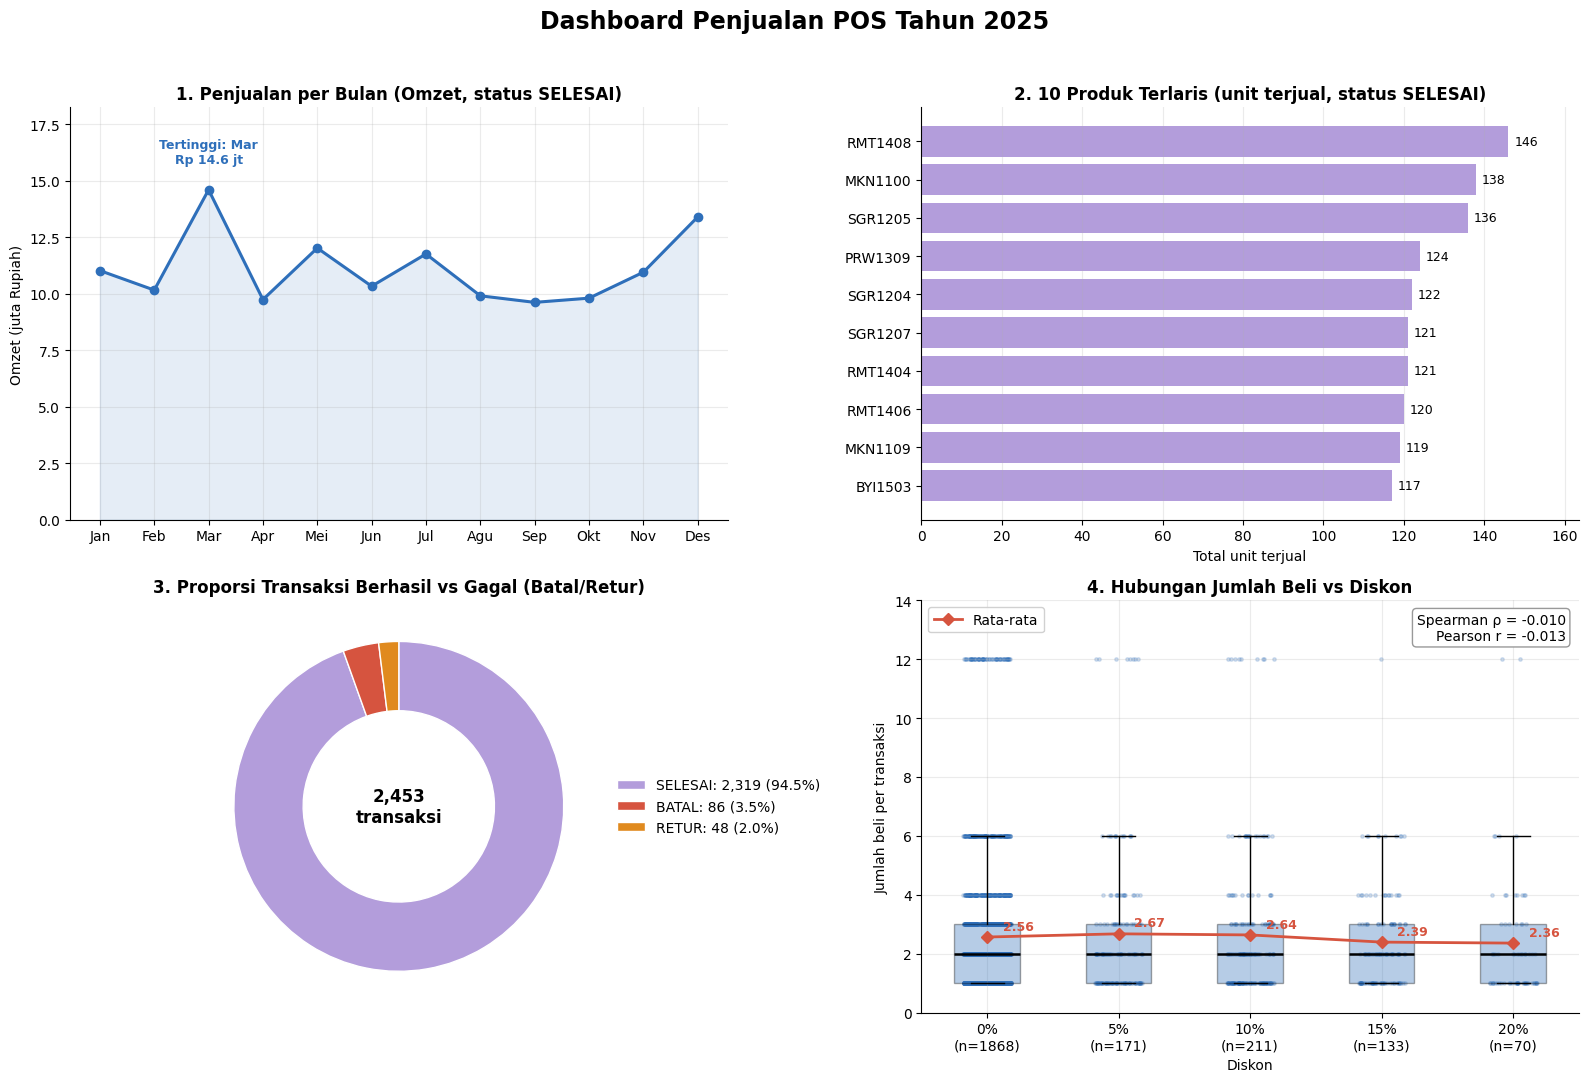

In [15]:
# Dashboard 2X2
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle("Dashboard Penjualan POS Tahun 2025", fontsize=17, fontweight="bold")

# BAGIAN 1: Penjualan per bulan (2025), hanya transaksi SELESAI
warna_garis = "#2E6FBA"

ax = axes[0, 0]
sel = d25[d25["status"] == "SELESAI"]
bulan = sel.groupby(sel["tanggal"].dt.month)["omzet"].sum().reindex(range(1, 13), fill_value=0)
nama_bulan = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]

fig.suptitle("Dashboard Penjualan POS Tahun 2025", fontsize=17, fontweight="bold")  # judul besar
ax.spines[["top", "right"]].set_visible(False)
ax.grid(True, alpha=0.25)

ax.plot(nama_bulan, bulan.values / 1e6, marker="o", color=warna_garis, linewidth=2.2)
ax.fill_between(nama_bulan, bulan.values / 1e6, alpha=0.12, color=warna_garis)
imax = int(bulan.values.argmax())
ax.annotate(f"Tertinggi: {nama_bulan[imax]}\nRp {bulan.values[imax]/1e6:,.1f} jt",
            xy=(imax, bulan.values[imax] / 1e6),
            xytext=(imax, bulan.values[imax] / 1e6 * 1.08),
            ha="center", fontsize=9, color=warna_garis, fontweight="bold")
ax.set_title("1. Penjualan per Bulan (Omzet, status SELESAI)", fontweight="bold")
ax.set_ylabel("Omzet (juta Rupiah)")
ax.set_ylim(0, bulan.max() / 1e6 * 1.25)

# BAGIAN 2: 10 produk terlaris 2025
warna_batang = "#B39DDB"

ax = axes[0, 1]
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.25)

top10 = (sel.groupby("kode_produk")["jumlah"].sum()
            .sort_values(ascending=False).head(10).sort_values())
bars = ax.barh(top10.index, top10.values, color=warna_batang)
for b, v in zip(bars, top10.values):
    ax.text(v + top10.max() * 0.01, b.get_y() + b.get_height() / 2,
            f"{int(v):,}", va="center", fontsize=9)
ax.set_title("2. 10 Produk Terlaris (unit terjual, status SELESAI)", fontweight="bold")
ax.set_xlabel("Total unit terjual")
ax.set_xlim(0, top10.max() * 1.12)

# BAGIAN 3: Proporsi transaksi berhasil vs gagal
warna_donut = ["#B39DDB",
               "#D6543F",
               "#E08A1E"]

ax = axes[1, 0]
rinci = d25["status"].value_counts().reindex(["SELESAI", "BATAL", "RETUR"], fill_value=0)
total = rinci.sum()

wedges, _ = ax.pie(rinci.values, colors=warna_donut, startangle=90,
                   counterclock=False, wedgeprops=dict(width=0.42, edgecolor="white"))
ax.text(0, 0, f"{total:,}\ntransaksi", ha="center", va="center", fontsize=12, fontweight="bold")
ax.legend(wedges,
          [f"{k}: {v:,} ({v/total:.1%})" for k, v in rinci.items()],
          loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
ax.set_title("3. Proporsi Transaksi Berhasil vs Gagal (Batal/Retur)", fontweight="bold")

# BAGIAN 4: Hubungan jumlah beli dengan diskon
warna_kotak = "#2E6FBA"
warna_rata  = "#D6543F"

ax = axes[1, 1]
ax.spines[["top", "right"]].set_visible(False)
ax.grid(True, alpha=0.25)

levels = sorted(d25["diskon_persen"].unique())
data_box = [d25.loc[d25["diskon_persen"] == l, "jumlah"] for l in levels]

bp = ax.boxplot(data_box, positions=range(len(levels)), widths=0.5,
                patch_artist=True, showfliers=False,
                medianprops=dict(color="black", linewidth=1.8))
for p in bp["boxes"]:
    p.set(facecolor=warna_kotak, alpha=0.35)

rng = np.random.default_rng(42)
for i, v in enumerate(data_box):
    ax.scatter(i + rng.uniform(-0.18, 0.18, len(v)), v, s=6, alpha=0.2, color=warna_kotak)
rata = [v.mean() for v in data_box]
ax.plot(range(len(levels)), rata, color=warna_rata, marker="D", linewidth=2, label="Rata-rata")
for i, r in enumerate(rata):
    ax.text(i + 0.12, r + 0.25, f"{r:.2f}", color=warna_rata, ha="left", fontsize=9, fontweight="bold")

rho = d25["jumlah"].corr(d25["diskon_persen"], method="spearman")
pear = d25["jumlah"].corr(d25["diskon_persen"], method="pearson")
ax.set_xticks(range(len(levels)))
ax.set_xticklabels([f"{l}%\n(n={len(v)})" for l, v in zip(levels, data_box)])
ax.set_xlabel("Diskon")
ax.set_ylabel("Jumlah beli per transaksi")
ax.set_title("4. Hubungan Jumlah Beli vs Diskon", fontweight="bold")
ax.set_ylim(0, 14)
ax.legend(loc="upper left", frameon=True, facecolor="white", framealpha=0.9)
ax.text(0.98, 0.97, f"Spearman ρ = {rho:.3f}\nPearson r = {pear:.3f}",
        transform=ax.transAxes, ha="right", va="top", fontsize=10,
        bbox=dict(boxstyle="round", facecolor="white", edgecolor="#999"))

# HASIL
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("dashboard_pos_2025.png", dpi=150, bbox_inches="tight")
plt.show()

#**RINGKASAN**

In [16]:
print("\n=== RINGKASAN 2025 ===")
print(f"Total omzet (SELESAI): Rp {bulan.sum():,.0f}")
print(f"Bulan tertinggi      : {nama_bulan[imax]}")
print("\nTop 10 produk:\n", top10.sort_values(ascending=False))
print("\nStatus transaksi:\n", rinci)
print(f"\nKorelasi jumlah-diskon: Spearman={rho:.3f}, Pearson={pear:.3f}")


=== RINGKASAN 2025 ===
Total omzet (SELESAI): Rp 133,221,575
Bulan tertinggi      : Mar

Top 10 produk:
 kode_produk
RMT1408    146
MKN1100    138
SGR1205    136
PRW1309    124
SGR1204    122
RMT1404    121
SGR1207    121
RMT1406    120
MKN1109    119
BYI1503    117
Name: jumlah, dtype: int64

Status transaksi:
 status
SELESAI    2319
BATAL        86
RETUR        48
Name: count, dtype: int64

Korelasi jumlah-diskon: Spearman=-0.010, Pearson=-0.013


#**KESIMPULAN**

Berdasarkan data transaksi POS tahun 2025, total omzet dari transaksi yang selesai mencapai sekitar Rp 133,2 juta. Penjualan paling tinggi terjadi di bulan Maret (sekitar Rp 14,6 juta), disusul Desember (sekitar Rp 13,4 juta). Penjualan paling rendah ada di pertengahan hingga akhir tahun, yaitu September sampai Oktober (sekitar Rp 9,6 sampai 9,8 juta), sehingga pola penjualannya naik turun dan tidak terus tumbuh sepanjang tahun.

Untuk produk, RMT1408 menjadi yang paling laris dengan 146 unit terjual. Berikutnya MKN1100 (138 unit) dan SGR1205 (136 unit). Selisih antar produk di 10 besar cukup tipis, yaitu 117 sampai 146 unit, jadi tidak ada satu produk yang mendominasi penjualan.

Dari sisi keberhasilan transaksi, sebagian besar transaksi berhasil, yaitu 94,5% berstatus selesai. Sisanya 3,5% dibatalkan dan 2,0% diretur, jadi total transaksi gagal hanya sekitar 5,5%. Angka ini menunjukkan operasional penjualan sudah berjalan baik.

Terakhir, jumlah barang yang dibeli hampir tidak berhubungan dengan besar diskon (korelasi Spearman sekitar −0,01). Rata-rata pembelian per transaksi relatif sama di semua tingkat diskon, yaitu sekitar 2,4 sampai 2,7 unit. Artinya, pemberian diskon yang lebih besar tidak mendorong pelanggan membeli lebih banyak, sehingga strategi diskon perlu dievaluasi agar tidak mengurangi keuntungan tanpa menambah volume penjualan.